# Polytope Lib Tests

In [2]:
from pycvxset import Polytope
import numpy as np
import matplotlib.pyplot as plt

import os
import mosek

os.environ["MOSEKLM_LICENSE_FILE"] = "27007@192.168.100.118"
mosek.Env().getversion()
mosek.Env().putlicensepath("27007@192.168.100.118")
mosek.Env().expirylicenses()

-1

In [3]:
from itertools import product
def cartesian_product(*polytopes):
    V_rep = [p.V for p in polytopes]
    Combinations = []
    for veritces in product(*V_rep):
        Combinations.append(np.concatenate(veritces))
    return Polytope(V=np.array(Combinations))

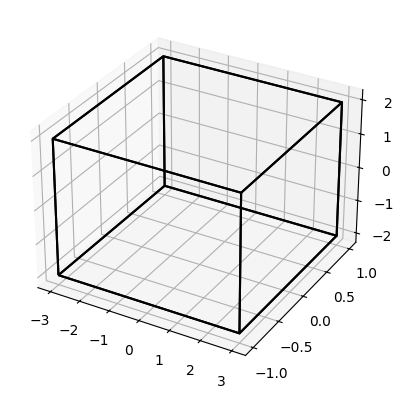

In [4]:
# Define the polytope using H-representation with 2D

A2 = np.array([[1, 0], [0, 1], [-1, 0], [0, -1]])
b2 = np.array([1, 2, 1, 2])

P_2D = Polytope(A=A2, b=b2)

# Define the polytope using H-representation with 1D

P_1D = Polytope(A=np.array([[1], [-1]]), b=np.array([3, 3]))

# Define the polytope using H-representation with 3D as Chartesian product of 1D and 2D

P = cartesian_product(P_1D, P_2D)


ax, _, _ = P.plot()
plt.show() 

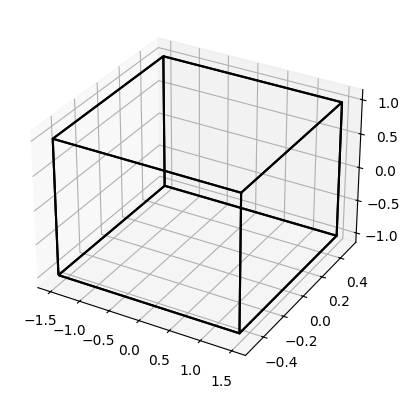

In [5]:
# Check proportional scalebility of sets

sigP = 0.5 * P

ax, _, _ = sigP.plot()
plt.show() 


# Casadi Tests

In [ ]:
import numpy as np
import casadi as ca 
from pycvxset import Polytope

In [ ]:
N = 30
n = 3
m = 2
op = ca.Opti()

x_opti =op.variable(n)
op.set_initial(x_opti,[1,2,3])
print(x_opti)

Q = ca.MX(np.array([[1,0,0],[0,2,0],[0,0,3]]))

# A = np.random(n,n)
# B = np.random(n.m)

x = ca.MX.sym('x',n,1,N)
x[0]=ca.MX(np.array([1,2,3]))
u = ca.MX.sym('u',m,1,N)
print(Q)
print(Q@x[0])
# constraint = []

# for i in range(N):

#     constraint.append(x[i+1]==A @ x[i] + B @ u[i])
#     ca.qpsol()



## Casadi - Solving a NLP with Opti

In [ ]:
opti = ca.Opti()

x = opti.variable()
y = opti.variable()

opti.minimize((y-x**2)**2)
opti.subject_to(x**2+y**2==1)
opti.subject_to(x+y>1)

opti.solver('ipopt')

sol = opti.solve()

print(sol.value(x))
print(sol.value(y))

## Casadi - Solving a NLP with MX

In [ ]:
x = ca.MX.sym('x')
y = ca.MX.sym('y')
f = (y-x**2)**2
g = ca.vertcat(x**2+y**2,x+y)
nlp = {'x':ca.vertcat(x,y), 'f':f, 'g':g}
s = ca.nlpsol('s', 'ipopt', nlp)
r = s(lbg=ca.vertcat(1,1), ubg=ca.vertcat(1,ca.inf))
x_opt = r['x']
print(x_opt)

# CVXPY LMI Solver

In [28]:
import cvxpy as cp
import numpy as np

import os
import mosek

os.environ["MOSEKLM_LICENSE_FILE"] = "27007@192.168.100.118"
mosek.Env().getversion()
mosek.Env().putlicensepath("27007@192.168.100.118")
mosek.Env().expirylicenses()

# Data
A = np.array([[0, 1], [-1, -2]])
n = 2

# Variables
P = cp.Variable((n, n), symmetric=True)

tol = cp.Parameter(1,"tol")

# Constraints
# P > 0 and A.T*P + P*A < 0 (using a small epsilon for strict inequality)
constraints = [P >> tol * np.eye(n), 
               A.T @ P + P @ A << -tol * np.eye(n)]

# Problem
prob = cp.Problem(cp.Minimize(0), constraints)
#prob.solve()

#print("Status:", prob.status)
#print("P:\n", P.value)


In [31]:
tol.value = [1e-6]
prob.solve()
print("Status:", prob.status)
print("P:\n", P.value)

Status: optimal
P:
 [[0.89116354 0.25811372]
 [0.25811372 0.38745421]]


In [33]:
import scipy as sc
l=cp.Parameter(1,"lambda")
print(l)
l.shape

A = np.array([[1,2],[2,1]]).transpose()
print(np.linalg.inv(A))

lambda
[[-0.33333333  0.66666667]
 [ 0.66666667 -0.33333333]]


In [54]:
rho = np.array([[.9, .1, 2]])

if np.isnan(rho).any():
    print("Hello")

np.isnan(rho).any()

np.False_